### Model Rollout Analysis
In this notebook, we analyze model rollout performance of both models (Pi05 and XR-1) across various settings:  
  
**1. With the final epoch model, we compare:** 
- Standard setting: same setting as in training (full light, box and tray can be moved around)
- Reduced Light: the two spotlights directly next to the arms are turned off
- Mat elevated: we elevated the mat, on which the box and tray are placed by approx. 4cm

**2. Comparison between training epochs:**
- 1st epoch
- 2nd epoch
- ...
- all trained on the same dataset, same starting point etc. 

In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats

In [2]:
Pi05_df = pd.read_csv('raw_data/Pi05_eval_robust.csv', delimiter=";")
XR1_df = pd.read_csv('raw_data/XR1_eval_robust.csv', delimiter=";")

In [3]:
Pi05_df.head()

,Run Name,Date,Attempt,Pin no.,Setting,Success_Overall,Grab_Success,Handover_Success,Put_Down_Success,Time(s)
0,pi05rel_full_ANTON_X_BOCCONI_clean4/006498,06/11/2026 17:22,#1,1,Standard,True,True,TRUE,True,20
1,pi05rel_full_ANTON_X_BOCCONI_clean4/006498,06/11/2026 17:22,#2,2,Standard,True,True,TRUE,True,25
2,pi05rel_full_ANTON_X_BOCCONI_clean4/006498,06/11/2026 17:22,#3,3,Standard,True,True,TRUE,True,20
3,pi05rel_full_ANTON_X_BOCCONI_clean4/006498,06/11/2026 17:22,#4,4,Standard,True,True,TRUE,True,19
4,pi05rel_full_ANTON_X_BOCCONI_clean4/006498,06/11/2026 17:22,#5,5,Standard,True,True,TRUE,True,20


In [4]:
XR1_df.head()

,Model Name,Date,Attempt,Setting,Pin no.,Success_Overall,Grab_Success,Handover_Success,Put_Down_Success,Time(s)
0,xr1full_ANTON_X_BOCCONI_clean4_20261106_1827/s...,13/11/2026 15:03,1,Foreign Object,1,WAHR,WAHR,WAHR,WAHR,25
1,xr1full_ANTON_X_BOCCONI_clean4_20261106_1827/s...,13/11/2026 15:03,2,Foreign Object,2,WAHR,WAHR,WAHR,WAHR,19
2,xr1full_ANTON_X_BOCCONI_clean4_20261106_1827/s...,13/11/2026 15:03,3,Foreign Object,3,WAHR,WAHR,WAHR,WAHR,17
3,xr1full_ANTON_X_BOCCONI_clean4_20261106_1827/s...,13/11/2026 15:03,4,Foreign Object,4,WAHR,WAHR,WAHR,WAHR,16
4,xr1full_ANTON_X_BOCCONI_clean4_20261106_1827/s...,13/11/2026 15:03,5,Foreign Object,5,WAHR,WAHR,WAHR,WAHR,17


In [5]:
print(f'No. of Pi05 obersvations: {len(Pi05_df)}')
print(f'No. of XR1 obersvations: {len(XR1_df)}')

No. of Pi05 obersvations: 200
No. of XR1 obersvations: 427


#### Convert Booleans columns to actual booleans:

In [6]:
bool_cols = [
    "Success_Overall",
    "Grab_Success",
    "Handover_Success",
    "Put_Down_Success"
]

bool_mapping = {
    "TRUE": True,
    "FALSE": False,
    "WAHR": True,
    "FALSCH": False
}

for df in [Pi05_df, XR1_df]:
    for col in bool_cols:
        df[col] = (
            df[col]
            .astype(str)
            .str.strip()
            .str.upper()
            .map(bool_mapping)
            .astype("boolean")
        )

#### Convert Setting names to unified convention

In [7]:
print("Before re-mapping:")
print(Pi05_df['Setting'].unique().tolist())
print(XR1_df['Setting'].unique().tolist())

XR1_df['Setting'] = XR1_df['Setting'].replace({
    'Foreign Object': 'Random Object',
    'Elevated Mat': 'Mat elevated',
    'Light off': 'No Light',
}).fillna('Standard')

print("After re-mapping:")
print(Pi05_df['Setting'].unique().tolist())
print(XR1_df['Setting'].unique().tolist())


Before re-mapping:
['Standard', 'No Light', 'Mat elevated', 'Random Object']
['Foreign Object', 'Light off', 'Elevated Mat', 'Top Camera Covered', nan]
After re-mapping:
['Standard', 'No Light', 'Mat elevated', 'Random Object']
['Random Object', 'No Light', 'Mat elevated', 'Top Camera Covered', 'Standard']


In [8]:
print(f" Pi05 Standard Success Rate: {Pi05_df[Pi05_df['Setting']=='Standard']['Success_Overall'].mean()*100:.2f}%")
print(f" Pi05 Success Rate w/ light off: {Pi05_df[Pi05_df['Setting']=='No Light']['Success_Overall'].mean()*100:.2f}%")
print(f" Pi05 Success Rate w/ mat elevated: {Pi05_df[Pi05_df['Setting']=='Mat elevated']['Success_Overall'].mean()*100:.2f}%")
print(f" Pi05 Success Rate w/ Random object: {Pi05_df[Pi05_df['Setting']=='Random Object']['Success_Overall'].mean()*100:.2f}%")
print("\n")
print(f" XR1 Standard Success Rate: {XR1_df[XR1_df['Setting']=='Standard']['Success_Overall'].mean()*100:.2f}%")
print(f" XR1 Success Rate w/ light off: {XR1_df[XR1_df['Setting']=='No Light']['Success_Overall'].mean()*100:.2f}%")
print(f" XR1 Success Rate w/ mat elevated: {XR1_df[XR1_df['Setting']=='Mat elevated']['Success_Overall'].mean()*100:.2f}%")
print(f" XR1 Success Rate w/ Random Object: {XR1_df[XR1_df['Setting']=='Random Object']['Success_Overall'].mean()*100:.2f}%")

 Pi05 Standard Success Rate: 90.00%
 Pi05 Success Rate w/ light off: 82.00%
 Pi05 Success Rate w/ mat elevated: 96.00%
 Pi05 Success Rate w/ Random object: 88.00%


 XR1 Standard Success Rate: 97.06%
 XR1 Success Rate w/ light off: 95.40%
 XR1 Success Rate w/ mat elevated: 96.00%
 XR1 Success Rate w/ Random Object: 86.00%


In [9]:
print(f"Success Rate Grabbing: {Pi05_df['Grab_Success'].mean()*100:.2f}%")
print(f"Success Rate Handover: {Pi05_df['Handover_Success'].mean()*100:.2f}%")
print(f"Success Rate Putting down: {Pi05_df['Put_Down_Success'].mean()*100:.2f}%")
print("\n")
print(f"Success Rate Grabbing: {XR1_df['Grab_Success'].mean()*100:.2f}%")
print(f"Success Rate Handover: {XR1_df['Handover_Success'].mean()*100:.2f}%")
print(f"Success Rate Putting down: {XR1_df['Put_Down_Success'].mean()*100:.2f}%")

Success Rate Grabbing: 96.00%
Success Rate Handover: 95.83%
Success Rate Putting down: 96.74%


Success Rate Grabbing: 96.49%
Success Rate Handover: 99.03%
Success Rate Putting down: 99.26%


### Figures for the paper

Success rates are the share of recorded attempts marked successful.  
Completion time uses successful attempts with a numeric time.

In [10]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats

set_matplotlib_formats("svg")

# Compact dimensions and embedded TrueType fonts suit most journal layouts.
plt.rcParams.update({
    "font.family": "DejaVu Serif",
    "font.size": 13,
    "axes.labelsize": 15,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "axes.linewidth": 1,
    "xtick.major.width": 1,
    "ytick.major.width": 1,
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.dpi": 300,
})

figure_dir = Path("..") / "Results" / "robustness_evaluation"
figure_dir.mkdir(exist_ok=True)
model_order = ["Pi05", "XR-1 (all variants)"]
setting_order = ["Standard", "No Light", "Mat elevated", "Random Object"]
step_columns = {
    "Grab_Success": "Grab",
    "Handover_Success": "Handover",
    "Put_Down_Success": "Put down",
}
model_colors = ["#242424", "#969696"]

def style_axes(ax, grid_axis="y"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis=grid_axis, color="#dddddd", linewidth=0.45)
    ax.tick_params(direction="out")

results = pd.concat(
    [Pi05_df.assign(Model=model_order[0]), XR1_df.assign(Model=model_order[1])],
    ignore_index=True,
)
results["Time(s)"] = pd.to_numeric(results["Time(s)"], errors="coerce")
results["Pin no."] = pd.to_numeric(results["Pin no."], errors="coerce")
completed = results.loc[results["Success_Overall"].fillna(False)].copy()
completed = completed.dropna(subset=["Time(s)"])

#### Overall success rate by setting

The “Top Camera Covered” setting has two XR-1 attempts and no Pi05 attempts.

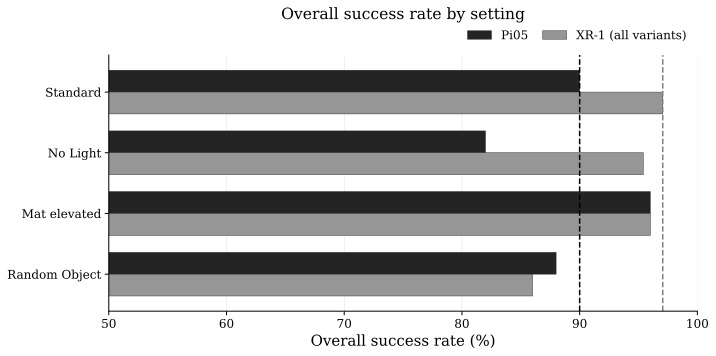

In [11]:
setting_rates = (
    results.groupby(["Setting", "Model"])["Success_Overall"]
    .mean().unstack("Model").mul(100)
    .reindex(index=setting_order, columns=model_order)
    .dropna(how="all")
)
fig, ax = plt.subplots(figsize=(10, 5))
setting_rates.plot.barh(ax=ax, width=0.72, color=model_colors, edgecolor="#242424", linewidth=0.45)

ax.invert_yaxis()
ax.set(xlabel="Overall success rate (%)", ylabel="", xlim=(0, 100))
ax.set_xticks(range(0, 101, 10))
ax.legend(title=None, frameon=False, loc="lower right",
          bbox_to_anchor=(1, 1.01), ncol=2, columnspacing=1.2)
ax.set_xlim(50, 100)
style_axes(ax, grid_axis="x")
ax.set_title("Overall success rate by setting", pad=36)
fig.tight_layout(pad=0.7)

pi05_standard = Pi05_df.loc[
    Pi05_df['Setting'] == 'Standard', 'Success_Overall'
].mean() * 100

xr1_standard = XR1_df.loc[
    XR1_df['Setting'] == 'Standard', 'Success_Overall'
].mean() * 100

# Add vertical reference lines
ax.axvline(pi05_standard, color='black',
           linestyle='--', linewidth=1.5,
           label='Pi0.5 Standard')

ax.axvline(xr1_standard, color='gray',
           linestyle='--', linewidth=1.5,
           label='XR-1 Standard')

fig.savefig(figure_dir / "success_by_setting.png", bbox_inches="tight")
plt.show()

#### Success rate by task step

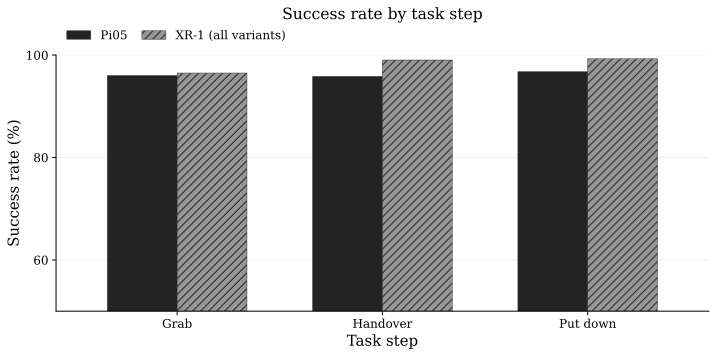

In [12]:
step_rates = (
    results.groupby("Model")[list(step_columns)]
    .mean().rename(columns=step_columns).T.mul(100)
    .reindex(columns=model_order)
)
fig, ax = plt.subplots(figsize=(10, 5))
step_rates.plot.bar(ax=ax, width=0.68, color=model_colors, edgecolor="#242424", linewidth=0.45)
for bar in ax.containers[1]:
    bar.set_hatch("///")
ax.set(xlabel="Task step", ylabel="Success rate (%)", ylim=(0, 100))
ax.set_yticks(range(0, 101, 20))
ax.tick_params(axis="x", rotation=0)
ax.legend(title=None, frameon=False, loc="lower left",
          bbox_to_anchor=(0, 1.01), ncol=2, columnspacing=1.2)
ax.set_ylim(50, 100)
style_axes(ax)
ax.set_title("Success rate by task step", pad=36)
fig.tight_layout(pad=0.7)
fig.savefig(figure_dir / "success_by_step.png", bbox_inches="tight")
plt.show()

#### Mean completion time by model (only considering successful episodes)

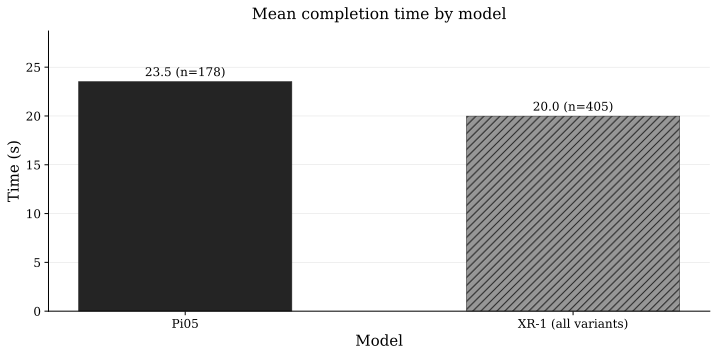

In [13]:
time_summary = completed.groupby("Model")["Time(s)"].agg(["mean", "count"]).reindex(model_order)
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar([0, 1], time_summary["mean"], width=0.55, color=model_colors,
              edgecolor="#242424", linewidth=0.5)
bars[1].set_hatch("///")
for bar, count in zip(bars, time_summary["count"]):
    ax.annotate(f"{bar.get_height():.1f} (n={int(count)})",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom", xytext=(0, 3), textcoords="offset points", fontsize=12)
ax.set(xticks=[0, 1], xticklabels=model_order, xlabel="Model", ylabel="Time (s)")
ax.set_ylim(0, time_summary["mean"].max() * 1.22)
style_axes(ax)
ax.set_title("Mean completion time by model", pad=12)
fig.tight_layout(pad=0.7)
fig.savefig(figure_dir / "mean_completion_time.png", bbox_inches="tight")
plt.show()

#### Mean completion time by pin number

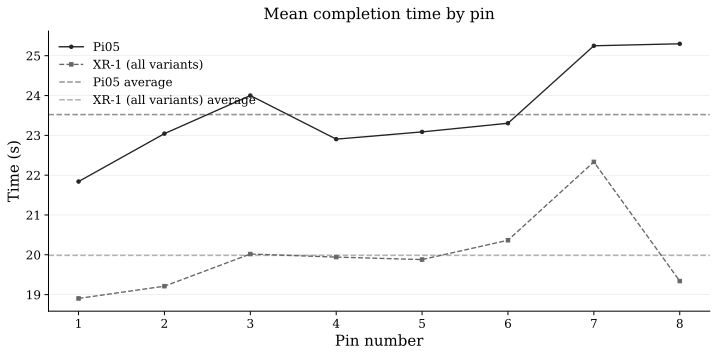

In [14]:
pin_times = (
    completed.groupby(["Pin no.", "Model"])["Time(s)"]
    .mean().unstack("Model").reindex(columns=model_order)
)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(pin_times.index, pin_times[model_order[0]], color=model_colors[0],
        marker="o", markersize=3.5, linewidth=1.35, label=model_order[0])
ax.plot(pin_times.index, pin_times[model_order[1]], color="#666666",
        marker="s", markersize=3.5, linewidth=1.35, linestyle="--", label=model_order[1])
ax.set(xlabel="Pin number", ylabel="Time (s)", xticks=pin_times.index)

ax.axhline(completed.loc[completed["Model"] == model_order[0], "Time(s)"].mean(),
           color=model_colors[0], linestyle="--", alpha=0.5, label=f"{model_order[0]} average")

ax.axhline(completed.loc[completed["Model"] == model_order[1], "Time(s)"].mean(),
           color="#666666", linestyle="--", alpha=0.5, label=f"{model_order[1]} average")

ax.legend(title=None, frameon=False, loc="upper left")

style_axes(ax)
ax.set_title("Mean completion time by pin", pad=12)
fig.tight_layout(pad=0.7)
fig.savefig(figure_dir / "completion_time_by_pin.png", bbox_inches="tight")
plt.show()

#### Distribution of failed attempts by task step

Each bar represents all failed attempts for one model (100%). A failed attempt is assigned once, to its **first failed step**. Steps not reached after a failure are not counted again.

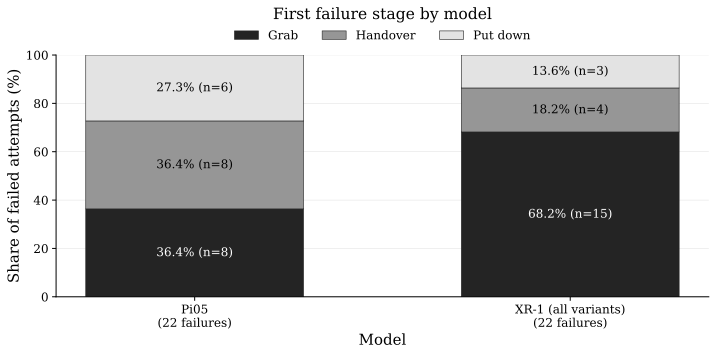

In [15]:
failure_steps = [("Grab_Success", "Grab"),
                 ("Handover_Success", "Handover"),
                 ("Put_Down_Success", "Put down")]
failed = results.loc[results["Success_Overall"].eq(False)].copy()
failed["First failed step"] = pd.NA
for column, step in failure_steps:
    first_failure = failed["First failed step"].isna() & failed[column].eq(False).fillna(False)
    failed.loc[first_failure, "First failed step"] = step
if failed["First failed step"].isna().any():
    raise ValueError("Some failed attempts have no recorded failed step.")

failure_counts = (
    failed.groupby(["Model", "First failed step"]).size().unstack(fill_value=0)
    .reindex(index=model_order, columns=[step for _, step in failure_steps], fill_value=0)
)
failure_shares = failure_counts.div(failure_counts.sum(axis=1), axis=0).mul(100)

fig, ax = plt.subplots(figsize=(10, 5))
segment_colors = ["#242424", "#969696", "#e3e3e3"]
bottoms = [0.0] * len(model_order)
for j, step in enumerate(failure_counts.columns):
    heights = failure_shares[step].to_numpy(dtype=float)
    bars = ax.bar(range(len(model_order)), heights, bottom=bottoms, width=0.58,
                  label=step, color=segment_colors[j], edgecolor="#242424",
                  linewidth=0.6)
    for k, bar in enumerate(bars):
        if heights[k] > 0:
            ax.text(bar.get_x() + bar.get_width() / 2, bottoms[k] + heights[k] / 2,
                    f"{heights[k]:.1f}% (n={failure_counts.iloc[k, j]})",
                    ha="center", va="center", fontsize=12,
                    color="white" if j == 0 else "black")
    bottoms = [base + height for base, height in zip(bottoms, heights)]
ax.set(xticks=range(len(model_order)),
       xticklabels=[f"{model}\n({failure_counts.loc[model].sum()} failures)" for model in model_order],
       xlabel="Model", ylabel="Share of failed attempts (%)", ylim=(0, 100))
ax.set_yticks(range(0, 101, 20))
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=3)
style_axes(ax)
ax.set_title("First failure stage by model", pad=36)
fig.tight_layout(pad=0.7)
fig.savefig(figure_dir / "failure_distribution_by_model.png", bbox_inches="tight")
plt.show()

#### Median completion time by setting

Points show the median time among successful attempts. Error bars show ±1 sample standard deviation of the observed times (descriptive spread, not a confidence interval). All currently recorded XR-1 times, including those in the Random Object setting, are numeric.

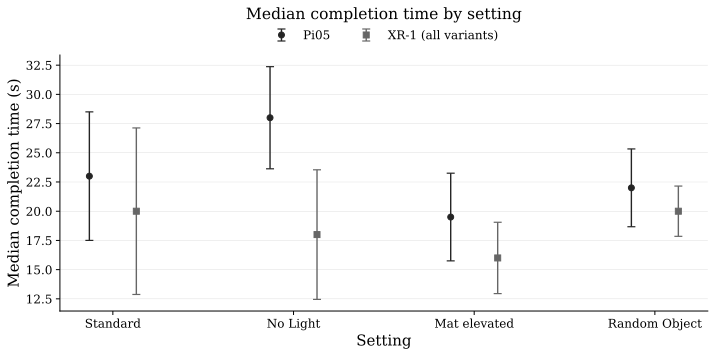

In [16]:
time_by_setting = (
    completed.groupby(["Setting", "Model"])["Time(s)"]
    .agg(["median", "std", "count"])
    .reindex(pd.MultiIndex.from_product([setting_order, model_order], names=["Setting", "Model"]))
)

fig, ax = plt.subplots(figsize=(10, 5))
positions = range(len(setting_order))
for model, offset, marker, color in [
    (model_order[0], -0.13, "o", model_colors[0]),
    (model_order[1], 0.13, "s", "#666666"),
]:
    summary = time_by_setting.xs(model, level="Model")
    x = [position + offset for position in positions]
    ax.errorbar(x, summary["median"], yerr=summary["std"], fmt=marker,
                linestyle="none", color=color, ecolor=color, markersize=6,
                elinewidth=1.4, capsize=4, capthick=1.2, label=model)
ax.set(xticks=list(positions), xticklabels=setting_order,
       xlabel="Setting", ylabel="Median completion time (s)")
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=2)
style_axes(ax)
ax.set_title("Median completion time by setting", pad=36)
fig.tight_layout(pad=0.7)
fig.savefig(figure_dir / "median_completion_time_by_setting.png", bbox_inches="tight")
plt.show()